<a href="https://colab.research.google.com/github/YassineGasmi04/AdultProject-ML-/blob/main/TP_capital_gain_membre6_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/YassineGasmi04/AdultProject-ML-/blob/main/TP_capital_gain_membre6_simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Étape 0 : Importer le fichier dans Colab

Cette cellule ouvre une fenêtre pour choisir le fichier CSV sur l'ordinateur. Le nom du fichier s'affiche ensuite sous la cellule.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving adult.data to adult.data


## Importer les bibliothèques

* **pandas** et **numpy** : manipuler les données.
* **matplotlib** et **seaborn** : faire des graphiques.
* **scipy** : faire le test du khi-deux (utilisé plus loin pour mesurer le lien entre une variable texte et la cible).
* **sklearn** : encoder et normaliser les données.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder, StandardScaler

## Charger le dataset

On lit le fichier CSV. Dans ce dataset, les valeurs inconnues sont écrites avec un point d'interrogation `?`. On demande à pandas de les considérer comme des valeurs manquantes avec `na_values='?'`.

`skipinitialspace=True` supprime les espaces au début des textes (par exemple `" Male"` devient `"Male"`).

Si le nom de ton fichier est différent, il suffit de le changer dans la première ligne.

In [3]:
FICHIER = "adult.data"

df = pd.read_csv(FICHIER, skipinitialspace=True, na_values='?')
df.shape

(32560, 15)

## Uniformiser les noms des colonnes

Selon la source du fichier, les colonnes peuvent s'appeler `capital-gain`, `capital.gain` ou `capital_gain`. On met tous les noms au même format (minuscules avec des tirets) pour que le reste du code fonctionne dans tous les cas.

La dernière ligne enlève le point final qui existe parfois dans la colonne `income` (`>50K.` devient `>50K`).

In [4]:


COLONNES = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
            'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
            'hours-per-week', 'native-country', 'income']

df = pd.read_csv(FICHIER, header=None, names=COLONNES, skipinitialspace=True, na_values='?')
df.shape

(32561, 15)

## Exploration des données

On regarde les premières lignes pour comprendre à quoi ressemblent les données.

In [5]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


On regarde les dernières lignes.

In [6]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
32560,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


On affiche les statistiques des variables numériques : moyenne, minimum, maximum, etc.

On remarque que pour `capital-gain`, la médiane (50 %) vaut 0 et même le 75 % vaut 0. Cela veut dire que la grande majorité des personnes n'a **aucun** gain en capital.

In [7]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


On affiche le type de chaque colonne et le nombre de valeurs non vides.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


# Partie 1 : Nettoyage des données

## Les doublons

Un doublon est une ligne qui est exactement identique à une autre. On compte d'abord combien il y en a.

In [9]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 24


On supprime les doublons, car ils comptent la même personne deux fois.

In [10]:
df = df.drop_duplicates()

On vérifie qu'il ne reste plus de doublons.

In [11]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


## Les valeurs manquantes

On compte le nombre de valeurs manquantes dans chaque colonne.

In [12]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


Trois colonnes ont des valeurs manquantes : `workclass`, `occupation` et `native-country`.

Ce sont des colonnes **texte**. On ne peut pas les remplacer par une moyenne. On choisit de remplacer les valeurs manquantes par le mot `Unknown` (inconnu). Ainsi, on ne supprime aucune personne et on n'invente pas de fausse information.

In [13]:
df['workclass'] = df['workclass'].fillna('Unknown')
df['occupation'] = df['occupation'].fillna('Unknown')
df['native-country'] = df['native-country'].fillna('Unknown')

df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


## Visualisation

On affiche l'histogramme de chaque variable numérique.

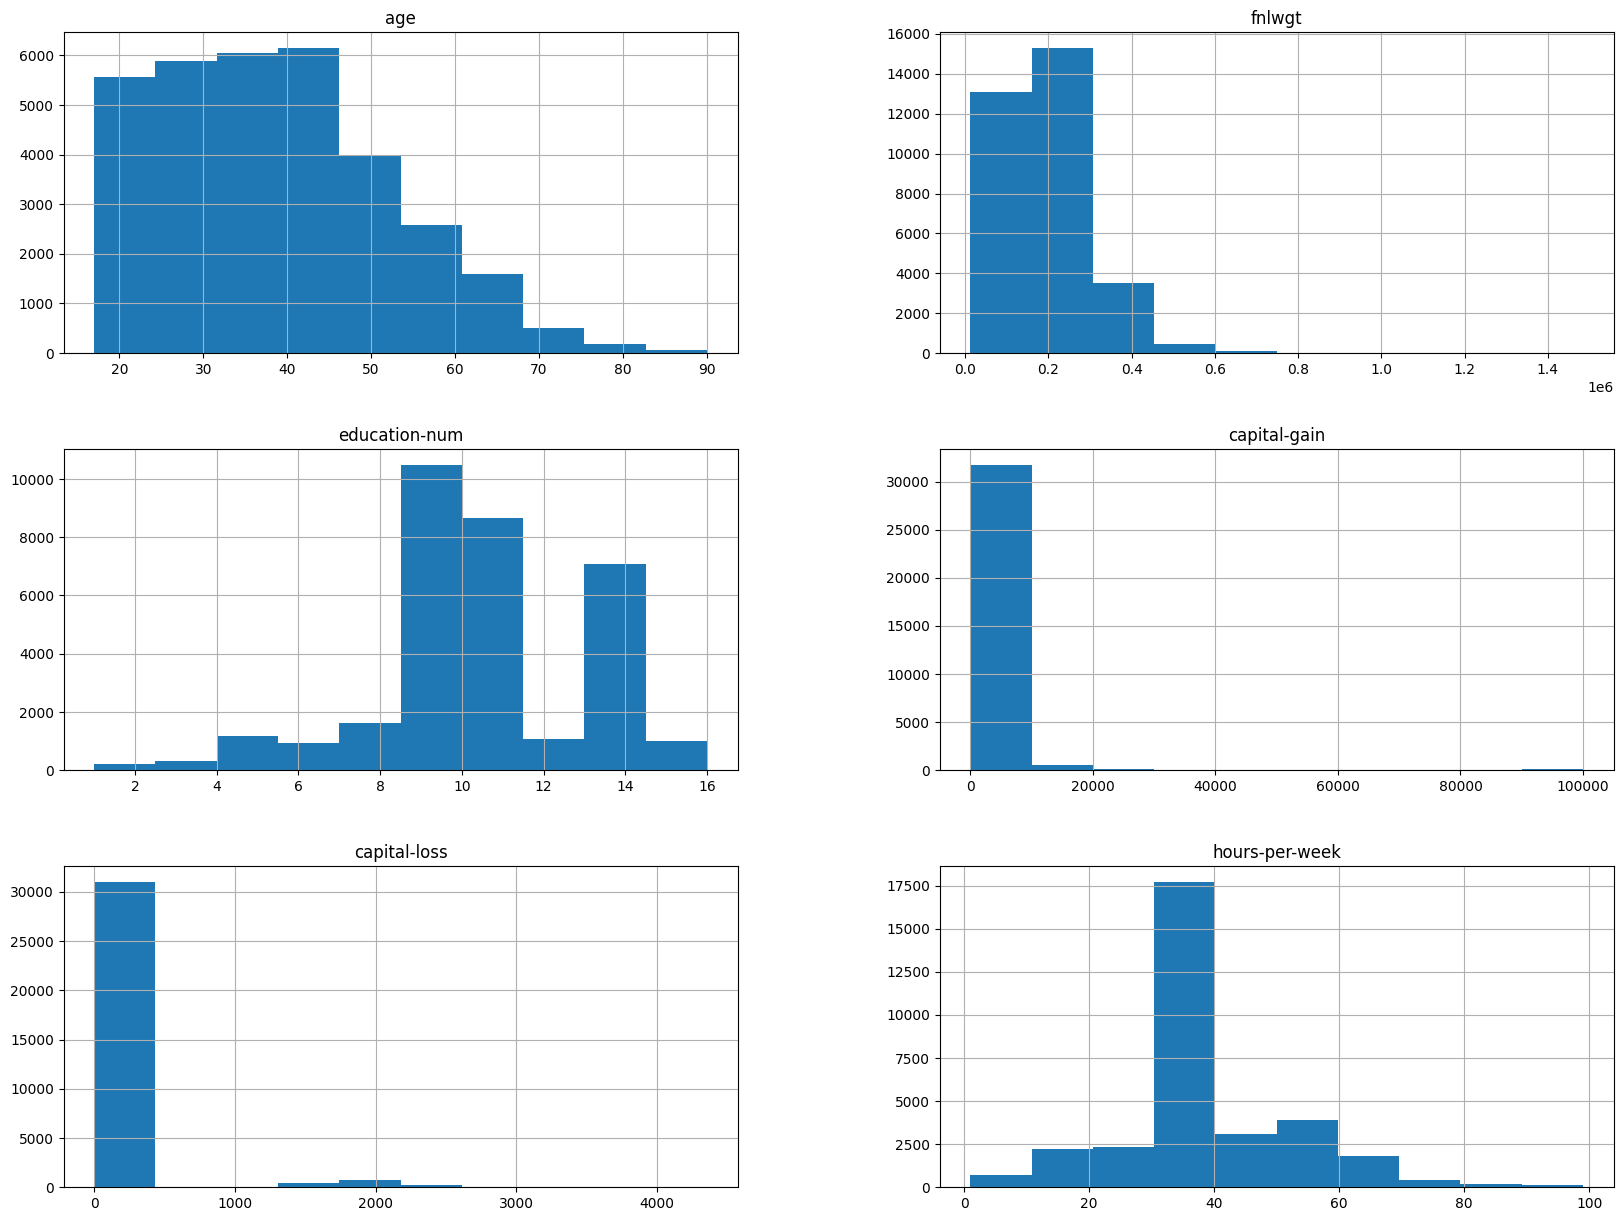

In [14]:
df.hist(figsize=(20, 15))
plt.show()

L'histogramme de `capital-gain` montre une seule grande barre à 0. Presque tout le monde a 0, et seules quelques personnes ont un montant.

C'est pour cette raison qu'on ne cherche pas à prédire le **montant** exact, mais seulement **si la personne a des gains ou non** (oui / non).

# Partie 2 : Création de la cible et des nouvelles variables

## Pourquoi cette partie vient avant la matrice de corrélation ?

* La variable cible n'est pas trouvée par la matrice : elle est **imposée par l'objectif métier** (ligne 6 du tableau).
* Notre cible (« a des gains : oui / non ») **n'existe pas encore** dans le fichier. Il faut la créer pour que la matrice puisse mesurer le lien entre les variables et la cible.
* Les nouvelles variables demandées (tranche d'âge, marié, niveau d'études regroupé) doivent aussi être créées **avant** la matrice, pour pouvoir vérifier si elles sont utiles.

## Créer la variable cible

On crée une nouvelle colonne `has_capital_gain` :
* **1** si `capital-gain` est supérieur à 0 (la personne a des gains en capital) ;
* **0** sinon.

In [15]:
df['has_capital_gain'] = (df['capital-gain'] > 0).astype(int)
target = 'has_capital_gain'

df[target].value_counts()

,count
has_capital_gain,
0,29825
1,2712


On affiche la proportion de chaque classe en pourcentage.

In [16]:
df[target].value_counts(normalize=True) * 100

,proportion
has_capital_gain,
0,91.664874
1,8.335126


On visualise la répartition de la cible.

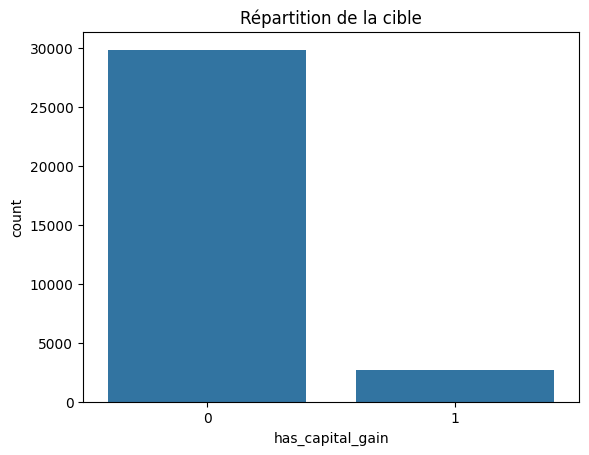

In [17]:
sns.countplot(x=target, data=df)
plt.title("Répartition de la cible")
plt.show()

Seulement environ **8 %** des personnes ont des gains en capital. On dit que la cible est **déséquilibrée**.

C'est important pour la suite : un modèle qui répond toujours « non » aurait 92 % de bonnes réponses tout en étant inutile. Lors de la modélisation, il faudra donc regarder d'autres mesures que l'accuracy (par exemple le rappel ou le F1-score).

## Nouvelle variable 1 : la tranche d'âge

On découpe l'âge en groupes : 17-25, 26-35, 36-45, 46-55, 56-65 et 66+.

**Pourquoi ?** On s'attend à ce que l'épargne augmente avec l'âge, car une personne plus âgée a eu plus de temps pour économiser et investir.

In [18]:
df['tranche_age'] = pd.cut(df['age'],
                           bins=[16, 25, 35, 45, 55, 65, 100],
                           labels=['17-25', '26-35', '36-45', '46-55', '56-65', '66+'])

df[['age', 'tranche_age']].head()

,age,tranche_age
0,39,36-45
1,50,46-55
2,38,36-45
3,53,46-55
4,28,26-35


## Nouvelle variable 2 : l'indicateur « marié »

On crée une colonne `est_marie` :
* **1** si la personne est mariée (`Married-civ-spouse` ou `Married-AF-spouse`) ;
* **0** sinon.

**Pourquoi ?** Un couple marié a souvent une épargne commune et des placements.

In [19]:
df['est_marie'] = df['marital-status'].isin(['Married-civ-spouse', 'Married-AF-spouse']).astype(int)

df[['marital-status', 'est_marie']].head()

,marital-status,est_marie
0,Never-married,0
1,Married-civ-spouse,1
2,Divorced,0
3,Married-civ-spouse,1
4,Married-civ-spouse,1


## Nouvelle variable 3 : le niveau d'études regroupé

La colonne `education` contient 16 niveaux différents, ce qui est beaucoup. On les regroupe en 5 niveaux en utilisant `education-num` (le niveau d'études sous forme de nombre, de 1 à 16) :

| education-num | Groupe |
|---|---|
| 1 à 8 | 1-Sans diplôme secondaire |
| 9 | 2-HS-grad (équivalent du bac) |
| 10 à 12 | 3-Études sup. courtes |
| 13 | 4-Bachelors (licence) |
| 14 à 16 | 5-Master et plus |

**Pourquoi ?** Moins de catégories rend la variable plus simple à utiliser et à interpréter.

In [20]:
def regrouper_education(n):
    if n <= 8:
        return '1-Sans diplome secondaire'
    elif n == 9:
        return '2-HS-grad'
    elif n <= 12:
        return '3-Etudes sup. courtes'
    elif n == 13:
        return '4-Bachelors'
    else:
        return '5-Master et plus'

df['education_groupe'] = df['education-num'].apply(regrouper_education)

df[['education', 'education-num', 'education_groupe']].head()

,education,education-num,education_groupe
0,Bachelors,13,4-Bachelors
1,Bachelors,13,4-Bachelors
2,HS-grad,9,2-HS-grad
3,11th,7,1-Sans diplome secondaire
4,Bachelors,13,4-Bachelors


## Vérifier que les nouvelles variables sont utiles

Pour chaque nouvelle variable, on calcule le **pourcentage de personnes qui ont des gains en capital** dans chaque groupe. La ligne rouge représente la moyenne générale (environ 8 %).

Si les barres sont très différentes les unes des autres, cela veut dire que la variable aide à distinguer les personnes qui ont des gains de celles qui n'en ont pas.

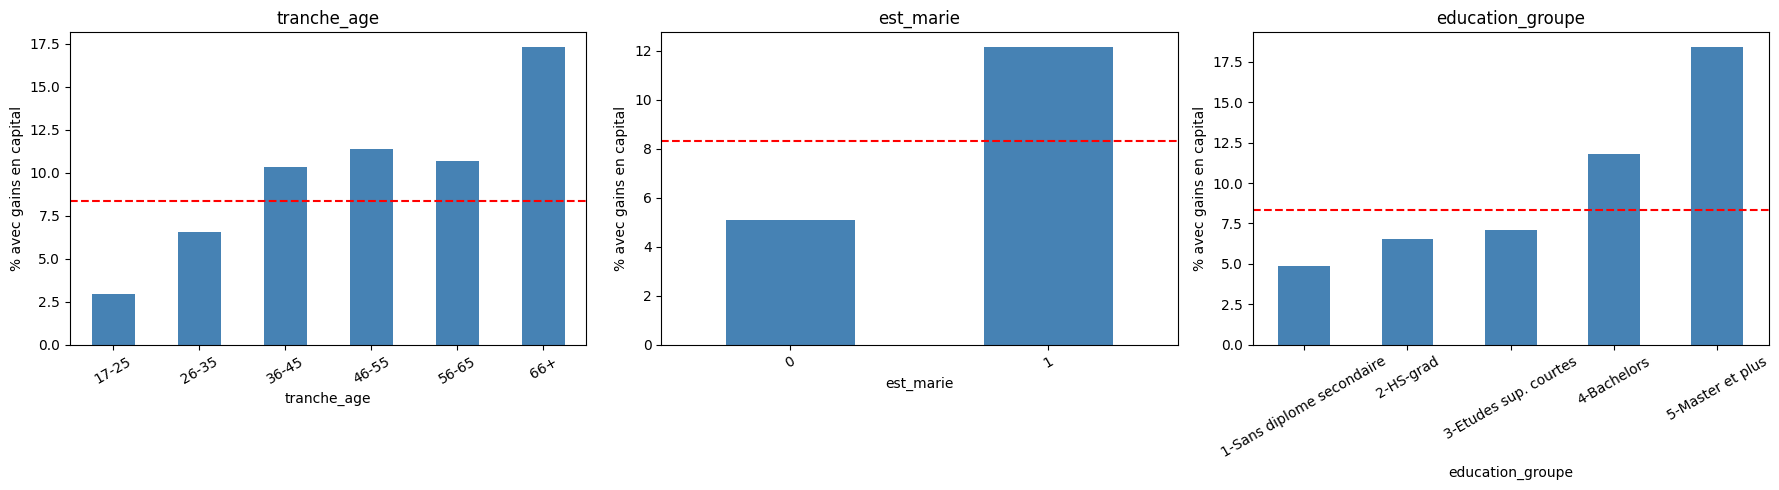

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['tranche_age', 'est_marie', 'education_groupe']):
    taux = df.groupby(col, observed=True)[target].mean() * 100
    taux.plot(kind='bar', ax=ax, color='steelblue')
    ax.axhline(df[target].mean() * 100, color='red', linestyle='--')
    ax.set_title(col)
    ax.set_ylabel("% avec gains en capital")
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Lecture des graphiques :**
* **Tranche d'âge :** environ 3 % chez les 17-25 ans, contre environ 16 % chez les 66 ans et plus.
* **Marié :** environ 12 % chez les mariés, contre 5 % chez les autres.
* **Niveau d'études :** environ 5 % sans diplôme secondaire, contre environ 18 % pour Master et plus.

Les trois nouvelles variables sont donc **utiles** pour notre cible.

## Retirer les variables qui « trichent » (fuite de données)

Une **fuite de données** se produit quand une variable contient déjà la réponse. Le modèle semblerait très bon pendant l'entraînement, mais il serait inutilisable dans la réalité.

On retire :
* **`capital-gain`** : c'est elle qui a servi à créer la cible. La garder reviendrait à donner directement la réponse au modèle.
* **`capital-loss`** : on vérifie juste en dessous qu'une personne qui a une perte en capital n'a **jamais** de gain. Le recensement n'enregistre qu'un seul montant (gain ou perte). Cette variable vient donc de la même information que la cible.
* **`income`** : le revenu inclut les gains en capital. Un gros gain fait automatiquement passer le revenu au-dessus de 50K. De plus, l'organisme ne connaît pas le revenu des personnes qu'il veut cibler.
* **`fnlwgt`** : c'est un poids statistique utilisé par le recensement. Il ne décrit pas la personne.

Vérification pour `capital-loss` : on croise « a une perte » avec « a un gain ».

In [22]:
pd.crosstab(df['capital-loss'] > 0, df[target])

has_capital_gain,0,1
capital-loss,,
False,28306,2712
True,1519,0


Dans la ligne `True` (personnes avec une perte), la colonne `1` vaut **0** : aucune personne avec une perte n'a de gain. Cela confirme la fuite de données.

On supprime maintenant ces quatre colonnes.

In [23]:
df = df.drop(columns=['capital-gain', 'capital-loss', 'income', 'fnlwgt'])
df.columns

Index(['age', 'workclass', 'education', 'education-num', 'marital-status',
       'occupation', 'relationship', 'race', 'sex', 'hours-per-week',
       'native-country', 'has_capital_gain', 'tranche_age', 'est_marie',
       'education_groupe'],
      dtype='object')

## Retirer les variables en double

Certaines variables contiennent la même information qu'une nouvelle variable que l'on a créée. On garde une seule variable par information, et on choisit la version créée :

| Information | On garde | On retire |
|---|---|---|
| Âge | `tranche_age` | `age` |
| Niveau d'études | `education_groupe` | `education`, `education-num` |
| Situation familiale | `est_marie` | `marital-status`, `relationship` |

`relationship` est retirée car ses valeurs principales (`Husband`, `Wife`) indiquent simplement que la personne est mariée.

In [24]:
df = df.drop(columns=['age', 'education', 'education-num', 'marital-status', 'relationship'])
df.columns

Index(['workclass', 'occupation', 'race', 'sex', 'hours-per-week',
       'native-country', 'has_capital_gain', 'tranche_age', 'est_marie',
       'education_groupe'],
      dtype='object')

# Partie 3 : Transformation des données

## Encodage des variables texte

Les modèles et la matrice de corrélation ne comprennent que les nombres. On transforme donc chaque variable texte en nombres avec `LabelEncoder` (par exemple `Female` devient 0 et `Male` devient 1), comme dans le TP.

On garde une copie `df_texte` des données en texte, car on en aura besoin à la Partie 4.

In [25]:
df['tranche_age'] = df['tranche_age'].astype(str)
df_texte = df.copy()

colonnes_texte = ['workclass', 'occupation', 'race', 'sex', 'native-country', 'tranche_age', 'education_groupe']

for col in colonnes_texte:
    df[col] = LabelEncoder().fit_transform(df[col])

df.head()

,workclass,occupation,race,sex,hours-per-week,native-country,has_capital_gain,tranche_age,est_marie,education_groupe
0,6,0,4,1,40,38,1,2,0,3
1,5,3,4,1,13,38,0,3,1,3
2,3,5,4,1,40,38,0,2,0,1
3,3,5,2,1,40,38,0,3,1,0
4,3,9,2,0,40,4,0,1,1,3


## Normalisation

On met toutes les variables sur la même échelle (moyenne 0, écart-type 1) avec `StandardScaler`, comme dans le TP. Par exemple, `hours-per-week` va de 1 à 99 alors que `est_marie` vaut 0 ou 1.

On ne normalise pas la cible, car elle doit rester 0 ou 1.

In [26]:
df_normalized = df.copy()
colonnes = df.columns.drop(target)
df_normalized[colonnes] = StandardScaler().fit_transform(df[colonnes])

df_normalized.head()

,workclass,occupation,race,sex,hours-per-week,native-country,has_capital_gain,tranche_age,est_marie,education_groupe
0,1.876197,-1.483535,0.393685,0.703020,-0.035664,0.257437,1,0.145212,-0.924443,1.107560
1,1.175970,-0.790564,0.393685,0.703020,-2.222483,0.257437,0,0.878531,1.081733,1.107560
2,-0.224485,-0.328584,0.393685,0.703020,-0.035664,0.257437,0,0.145212,-0.924443,-0.661025
3,-0.224485,-0.328584,-1.962488,0.703020,-0.035664,0.257437,0,0.878531,1.081733,-1.545317
4,-0.224485,0.595376,-1.962488,-1.422436,-0.035664,-5.352003,0,-0.588106,1.081733,1.107560


# Partie 4 : Sélection des caractéristiques

## Matrice de corrélation

La matrice de corrélation montre le lien entre chaque paire de variables. Une valeur proche de **1** ou **-1** indique un lien fort, une valeur proche de **0** indique un lien faible.

On s'intéresse surtout à la **dernière ligne/colonne**, celle de la cible `has_capital_gain`.

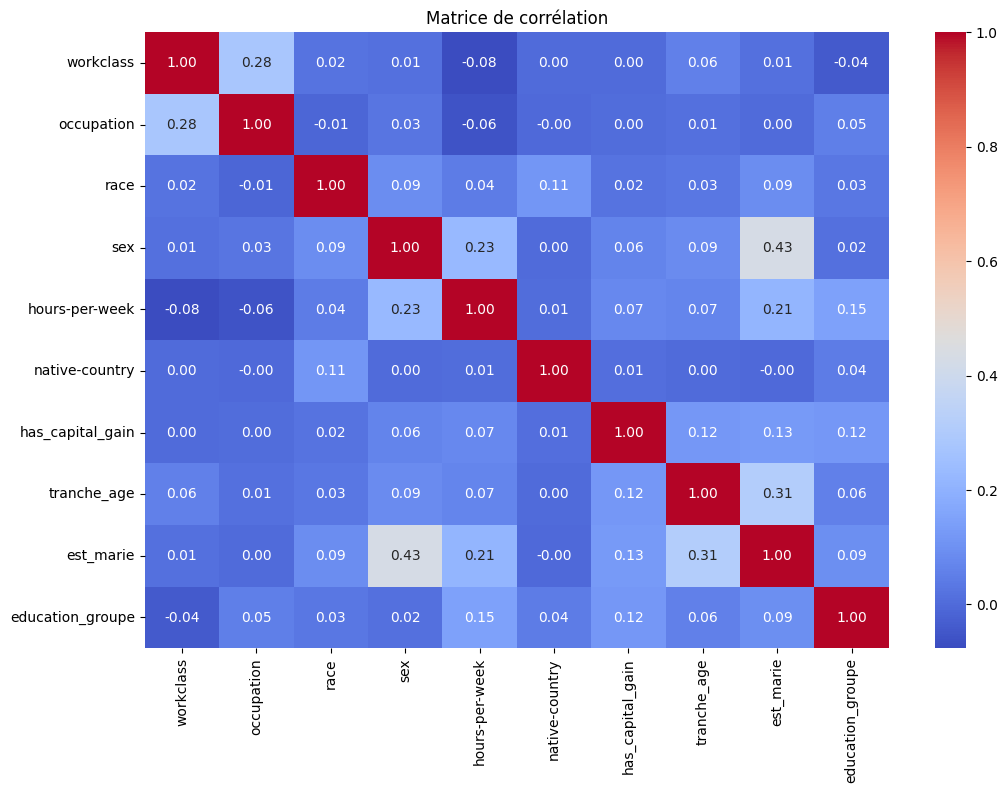

In [27]:
plt.figure(figsize=(12, 8))
corr_matrix = df_normalized.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matrice de corrélation')
plt.show()

## Corrélations avec la cible

On affiche uniquement la corrélation de chaque variable avec la cible. On prend la valeur absolue, car un lien négatif fort est aussi utile qu'un lien positif fort.

In [28]:
corr_matrix[target].abs().drop(target).sort_values(ascending=False)

,has_capital_gain
est_marie,0.127441
education_groupe,0.119634
tranche_age,0.118966
hours-per-week,0.074979
sex,0.064760
race,0.023615
native-country,0.011516
occupation,0.004422
workclass,0.000200


## Limite de la corrélation pour les variables texte

La corrélation fonctionne bien pour les variables qui sont de **vrais nombres** (`hours-per-week`) ou qui n'ont que **deux valeurs** (`est_marie`, `sex`).

Mais pour une variable texte avec beaucoup de catégories, comme `occupation`, le `LabelEncoder` a donné les numéros 0, 1, 2… **par ordre alphabétique**. Ces numéros n'ont pas de sens : `Adm-clerical` = 0 n'est pas « plus petit » que `Sales` = 11. La corrélation calculée sur ces numéros n'est donc pas fiable.

**Solution :** pour ces variables, on utilise le **V de Cramér**. C'est l'équivalent de la corrélation pour les variables texte. Il se calcule à partir du test du khi-deux et donne une valeur entre **0** (aucun lien) et **1** (lien parfait). Il ne dépend pas de l'ordre des catégories.

In [29]:
def v_de_cramer(x, y):
    tableau = pd.crosstab(x, y)
    chi2 = chi2_contingency(tableau)[0]
    n = tableau.values.sum()
    return np.sqrt(chi2 / (n * (min(tableau.shape) - 1)))

## Tableau final des scores

On calcule un score pour chaque variable :
* **Corrélation** (Pearson, celle de la matrice) pour les variables numériques ou à deux valeurs : `hours-per-week`, `est_marie`, `sex`.
* **V de Cramér** pour les variables texte à plusieurs catégories : on utilise `df_texte`, la copie gardée avant l'encodage.

In [30]:
variables_numeriques = ['hours-per-week', 'est_marie', 'sex']
variables_texte = ['tranche_age', 'education_groupe', 'occupation', 'workclass', 'race', 'native-country']

scores = {}
for col in variables_numeriques:
    scores[col] = abs(corr_matrix.loc[col, target])
for col in variables_texte:
    scores[col] = v_de_cramer(df_texte[col], df_texte[target])

scores = pd.Series(scores).sort_values(ascending=False).round(3)
scores

,0
education_groupe,0.133
tranche_age,0.128
est_marie,0.127
occupation,0.122
hours-per-week,0.075
workclass,0.073
sex,0.065
native-country,0.044
race,0.032


**Remarque importante :** dans la matrice de corrélation, `occupation` avait un score presque nul (environ 0.002), alors qu'avec le V de Cramér son score est d'environ 0.12. Cela montre bien que la corrélation calculée sur des numéros arbitraires peut cacher une variable utile.

On visualise ces scores. La ligne verte (0.10) est le seuil des variables **principales**, la ligne orange (0.05) le seuil des variables **secondaires**.

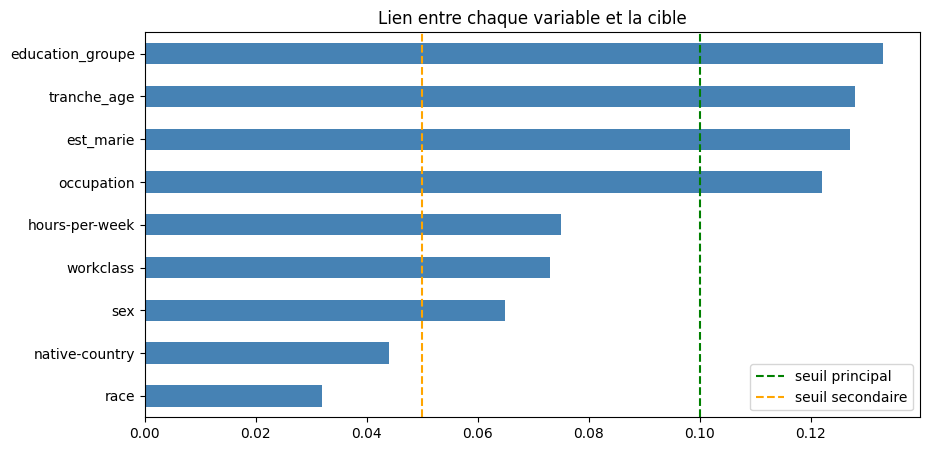

In [31]:
plt.figure(figsize=(10, 5))
scores.sort_values().plot(kind='barh', color='steelblue')
plt.axvline(0.10, color='green', linestyle='--', label='seuil principal')
plt.axvline(0.05, color='orange', linestyle='--', label='seuil secondaire')
plt.title("Lien entre chaque variable et la cible")
plt.legend()
plt.show()

## Choisir les caractéristiques principales et secondaires

On applique deux seuils, comme le seuil de 0.1 utilisé dans le TP :
* **Principales :** score supérieur ou égal à **0.10** (lien clair avec la cible).
* **Secondaires :** score entre **0.05** et **0.10** (lien plus faible mais présent).
* **Écartées :** score inférieur à **0.05** (lien trop faible).

In [32]:
features_principales = scores[scores >= 0.10].index.tolist()
features_secondaires = scores[(scores >= 0.05) & (scores < 0.10)].index.tolist()
features_ecartees = scores[scores < 0.05].index.tolist()

print("Principales :", features_principales)
print("Secondaires :", features_secondaires)
print("Écartées    :", features_ecartees)

Principales : ['education_groupe', 'tranche_age', 'est_marie', 'occupation']
Secondaires : ['hours-per-week', 'workclass', 'sex']
Écartées    : ['native-country', 'race']


## Conclusion de la sélection

| Rôle | Variable | Explication |
|---|---|---|
| **Principale** | `education_groupe` | Plus le niveau d'études est élevé, plus on a de gains en capital |
| **Principale** | `tranche_age` | Les personnes plus âgées ont plus souvent des gains |
| **Principale** | `est_marie` | Les personnes mariées ont deux fois plus souvent des gains |
| **Principale** | `occupation` | Les cadres et professions intellectuelles ont plus souvent des gains |
| **Secondaire** | `hours-per-week` | Lien plus faible avec la cible |
| **Secondaire** | `workclass` | Les indépendants ont plus souvent des gains |
| **Secondaire** | `sex` | Lien faible, à utiliser avec prudence (risque de ciblage discriminant) |
| Écartée | `race`, `native-country` | Lien trop faible, et ce sont des variables sensibles |
| Écartée | `capital-gain`, `capital-loss`, `income` | Fuite de données |
| Écartée | `fnlwgt` | Poids statistique sans signification pour la personne |

Les trois variables créées (tranche d'âge, marié, niveau d'études regroupé) font toutes partie des variables **principales**. Cela confirme les choix de l'objectif Data Science.

## Créer le DataFrame avec les caractéristiques sélectionnées

On garde uniquement les variables principales et secondaires, plus la cible, comme à la fin du TP.

In [33]:
df_selected = df_normalized[features_principales + features_secondaires + [target]]
df_selected.head()

,education_groupe,tranche_age,est_marie,occupation,hours-per-week,workclass,sex,has_capital_gain
0,1.107560,0.145212,-0.924443,-1.483535,-0.035664,1.876197,0.703020,1
1,1.107560,0.878531,1.081733,-0.790564,-2.222483,1.175970,0.703020,0
2,-0.661025,0.145212,-0.924443,-0.328584,-0.035664,-0.224485,0.703020,0
3,-1.545317,0.878531,1.081733,-0.328584,-0.035664,-0.224485,0.703020,0
4,1.107560,-0.588106,1.081733,0.595376,-0.035664,-0.224485,-1.422436,0


Enfin, on sépare les variables explicatives **X** et la cible **y**. Ce sont les données qui serviront à entraîner le modèle de classification à l'étape suivante.

In [34]:
X = df_selected.drop(columns=[target])
y = df_selected[target]

print("X :", X.shape)
print("y :", y.shape)

X : (32537, 7)
y : (32537,)


# Partie 5 : Modélisation (classification binaire)

**Objectif :** prédire si une personne a des gains en capital (`has_capital_gain` = 1) ou non (0).

**Type de problème :** c'est une **classification binaire**, car la cible n'a que deux valeurs. Pour résoudre ce problème, on compare **cinq algorithmes de classification binaire** et on retient le plus adapté.

**Démarche :**
1. Préparer les données d'entraînement et de test.
2. Tester **5 algorithmes** de classification binaire.
3. Les comparer avec des métriques adaptées à notre problème.
4. Choisir le modèle le plus adapté au **but de l'organisme d'éducation financière**.

**Ce qu'on attend, d'après la Partie 4 :** les scores de lien avec la cible sont faibles (environ 0.13 au maximum). Aucune variable ne permet à elle seule de savoir si une personne a des gains en capital. On ne doit donc **pas** espérer un modèle très précis. L'objectif réaliste est d'obtenir un modèle qui **classe les personnes de la plus probable à la moins probable**, pour que l'organisme cible en priorité les bons profils.

## Importer les outils de modélisation

* `train_test_split` : séparer les données en entraînement et test.
* `cross_validate` et `StratifiedKFold` : la validation croisée.
* `Pipeline` et `ColumnTransformer` : enchaîner la préparation et le modèle.
* `OneHotEncoder` : encoder les variables texte.
* Les 5 algorithmes : `DecisionTreeClassifier`, `RandomForestClassifier`, `HistGradientBoostingClassifier`, `KNeighborsClassifier`, `BernoulliNB`.
* `permutation_importance` : mesurer l'importance de chaque variable.
* `metrics` : les mesures de performance.

In [35]:
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import make_scorer
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

## Pourquoi on repart de `df_texte` et pas de `df_selected`

`df_selected` contient deux problèmes pour la modélisation :

1. **Le `LabelEncoder` crée un faux ordre.** Pour `occupation`, le métier n°11 n'est pas « plus grand » que le métier n°0. Un modèle pourrait pourtant utiliser ces numéros comme des quantités (par exemple « métier > 5 »). On utilise donc le **One-Hot Encoding** : une colonne 0/1 par catégorie.
2. **La normalisation a été calculée sur toutes les données**, y compris celles qui serviront au test. Le modèle aurait donc « vu » une information sur le jeu de test. Ici, la normalisation sera apprise **uniquement sur l'entraînement** grâce au `Pipeline`.

On garde exactement les **mêmes variables** que celles choisies à la Partie 4 (principales et secondaires).

In [36]:
variables_categorielles = [c for c in features_principales + features_secondaires if c in variables_texte or c == 'sex']
variables_numeriques_modele = [c for c in features_principales + features_secondaires if c not in variables_categorielles]

X = df_texte[variables_categorielles + variables_numeriques_modele]
y = df_texte[target]

print("Variables catégorielles :", variables_categorielles)
print("Variables numériques    :", variables_numeriques_modele)
print("X :", X.shape, "| y :", y.shape)

Variables catégorielles : ['education_groupe', 'tranche_age', 'occupation', 'workclass', 'sex']
Variables numériques    : ['est_marie', 'hours-per-week']
X : (32537, 7) | y : (32537,)


## Séparer les données : entraînement (80 %) et test (20 %)

* Le jeu d'**entraînement** sert à apprendre et à comparer les modèles.
* Le jeu de **test** est mis de côté. On ne l'utilise qu'**une seule fois**, à la fin, pour vérifier le modèle choisi sur des personnes qu'il n'a jamais vues.

`stratify=y` garde la même proportion de personnes avec gains (environ 8 %) dans les deux jeux. C'est important car la cible est déséquilibrée.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Entraînement :", X_train.shape, "- taux de positifs :", round(y_train.mean() * 100, 2), "%")
print("Test         :", X_test.shape, "- taux de positifs :", round(y_test.mean() * 100, 2), "%")

Entraînement : (26029, 7) - taux de positifs : 8.34 %
Test         : (6508, 7) - taux de positifs : 8.33 %


## Préparation automatique des données

Le `ColumnTransformer` applique :
* le **One-Hot Encoding** aux variables texte ;
* la **normalisation** (`StandardScaler`) aux variables numériques.

Il sera placé dans un `Pipeline` avec chaque modèle. Ainsi, la préparation est apprise sur l'entraînement seulement, puis appliquée telle quelle au test.

In [38]:
preparation = ColumnTransformer([
    ('texte', OneHotEncoder(handle_unknown='ignore', sparse_output=False), variables_categorielles),
    ('nombres', StandardScaler(), variables_numeriques_modele)
])

## Le piège de l'accuracy

Avant de tester les algorithmes, on regarde un « modèle » qui répond **toujours non** (personne n'a de gains).

In [39]:
predictions_toujours_non = np.zeros(len(y_test), dtype=int)

print("Accuracy :", round(accuracy_score(y_test, predictions_toujours_non), 3))
print("Rappel   :", round(recall_score(y_test, predictions_toujours_non), 3))

Accuracy : 0.917
Rappel   : 0.0


Ce « modèle » a environ **92 % d'accuracy**, mais un **rappel de 0** : il ne trouve aucune personne avec des gains. Il est donc inutile pour l'organisme.

**Conclusion :** l'accuracy n'est pas une bonne mesure ici. On utilisera :

| Mesure | Question à laquelle elle répond |
|---|---|
| **Rappel (recall)** | Parmi les personnes qui ont vraiment des gains, combien le modèle en trouve-t-il ? |
| **Précision** | Parmi les personnes que le modèle cible, combien ont vraiment des gains ? |
| **F1-score** | Un équilibre entre le rappel et la précision |
| **ROC-AUC** | Le modèle classe-t-il bien les personnes de la plus probable à la moins probable ? (0.5 = hasard, 1 = parfait) |

## Les 5 algorithmes testés

| Algorithme | Principe | Pourquoi le tester |
|---|---|---|
| **Arbre de décision** | Pose une suite de questions (« marié ? », « plus de 45 ans ? »…) pour arriver à une réponse | Le plus simple et le plus facile à expliquer |
| **Random Forest** | Construit 300 arbres différents et fait voter leurs réponses | Plus stable qu'un seul arbre, moins de risque de sur-apprentissage |
| **Gradient Boosting** | Construit des arbres l'un après l'autre, chacun corrigeant les erreurs du précédent | Souvent le plus performant sur des données en tableau |
| **K plus proches voisins (KNN)** | Regarde les 50 personnes au profil le plus proche et prend la réponse majoritaire | Méthode très différente des arbres, basée sur la ressemblance entre profils |
| **Naive Bayes** | Calcule une probabilité avec la formule de Bayes, en supposant les variables indépendantes | Très rapide, bien adapté aux variables 0/1 créées par le One-Hot Encoding |

**Gestion du déséquilibre :**
* pour les arbres, `class_weight='balanced'` donne plus d'importance aux personnes avec gains (8 %) ;
* pour Naive Bayes, `class_prior=[0.5, 0.5]` fait le même travail en donnant le même poids aux deux classes ;
* le **KNN n'a pas d'option équivalente**. On le garde tel quel pour voir l'effet du déséquilibre.

**Limiter le sur-apprentissage :** on limite la profondeur des arbres (`max_depth`) et le nombre minimum de personnes par feuille (`min_samples_leaf`). Sinon les arbres apprennent les données d'entraînement par cœur.

In [40]:
modeles = {
    'Arbre de décision': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                                class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=20,
                                            class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300,
                                                        class_weight='balanced', random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=50),
    'Naive Bayes': BernoulliNB(class_prior=[0.5, 0.5])
}

## Comparaison par validation croisée (5 plis)

La validation croisée découpe le jeu d'entraînement en 5 parties. Le modèle est entraîné 5 fois sur 4 parties et évalué sur la partie restante. On fait ensuite la moyenne des 5 scores.

C'est plus fiable qu'un seul essai, et cela permet de **choisir le modèle sans toucher au jeu de test**.

On affiche aussi le ROC-AUC sur les données d'**entraînement** : s'il est beaucoup plus haut que celui de la validation, le modèle a appris par cœur (sur-apprentissage).

In [41]:
validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mesures = {'Rappel': 'recall', 'Précision': make_scorer(precision_score, zero_division=0),
           'F1': 'f1', 'ROC-AUC': 'roc_auc'}

resultats = {}
for nom, modele in modeles.items():
    pipeline = Pipeline([('preparation', preparation), ('modele', modele)])
    scores_cv = cross_validate(pipeline, X_train, y_train, cv=validation, scoring=mesures, return_train_score=True)
    resultats[nom] = {m: scores_cv['test_' + m].mean() for m in mesures}
    resultats[nom]['ROC-AUC entraînement'] = scores_cv['train_ROC-AUC'].mean()

tableau_cv = pd.DataFrame(resultats).T.round(3)
tableau_cv

,Rappel,Précision,F1,ROC-AUC,ROC-AUC entraînement
Arbre de décision,0.658,0.130,0.216,0.676,0.702
Random Forest,0.629,0.140,0.229,0.696,0.743
Gradient Boosting,0.658,0.134,0.222,0.691,0.726
KNN,0.000,0.000,0.000,0.665,0.738
Naive Bayes,0.662,0.134,0.222,0.688,0.692


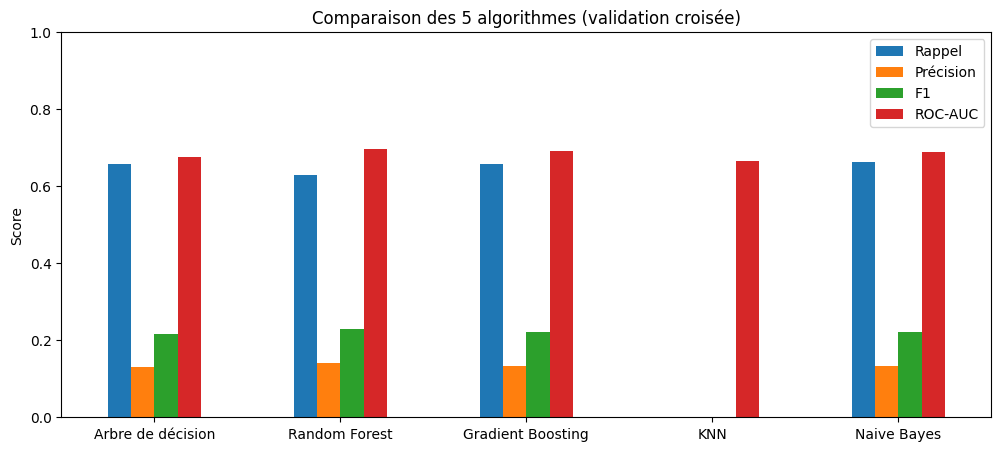

In [42]:
tableau_cv[['Rappel', 'Précision', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(12, 5))
plt.title("Comparaison des 5 algorithmes (validation croisée)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='upper right')
plt.show()

## Lecture des résultats

* Le **KNN** a un rappel de **0** : il ne trouve aucune personne avec gains. Comme 92 % des voisins d'une personne n'ont pas de gains, la majorité répond toujours « non ». C'est exactement le piège du déséquilibre vu plus haut. Son ROC-AUC (0.661) est aussi le plus faible. Il est donc **rejeté**.
* **Naive Bayes** obtient des résultats corrects (F1 0.222, ROC-AUC 0.688), mais il suppose que les variables sont indépendantes, ce qui est faux ici (l'âge et le fait d'être marié sont liés, par exemple).
* L'**arbre de décision** seul est trop simple et instable (ROC-AUC 0.676).
* La **Random Forest** obtient le meilleur **F1** (0.224) et le meilleur **ROC-AUC** (0.696). C'est elle qui classe le mieux les personnes.
* Le **Gradient Boosting** est très proche de la Random Forest, mais légèrement en dessous.
* Pour la Random Forest, l'écart entre entraînement et validation reste modéré (environ 0.04) : il n'y a **pas de sur-apprentissage important**.

**Pourquoi les scores restent modestes ?** C'est cohérent avec la Partie 4 : nos variables ont un lien faible avec la cible (environ 0.13). Avoir des gains en capital dépend surtout d'informations absentes du dataset (patrimoine, héritage, épargne). Un ROC-AUC d'environ 0.70 reste nettement meilleur que le hasard (0.50) : le modèle sait **classer** les personnes, même s'il ne peut pas prédire avec certitude.

## Choix du modèle : la Random Forest

On choisit la **Random Forest** pour trois raisons liées au but de l'organisme :

1. **Meilleures performances** parmi les 5 algorithmes en validation croisée : meilleur F1 et meilleur ROC-AUC, avec un bon rappel.
2. **Stable** : comme elle fait voter 300 arbres, elle dépend moins des particularités des données qu'un arbre seul.
3. **Interprétable** : on peut mesurer l'importance de chaque variable (voir plus bas). L'organisme peut ainsi comprendre quels critères guident le ciblage.

In [43]:
modele_choisi = Pipeline([('preparation', preparation), ('modele', modeles['Random Forest'])])
modele_choisi.fit(X_train, y_train)

Pipeline(steps=[('preparation',
                 ColumnTransformer(transformers=[('texte',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['education_groupe',
                                                   'tranche_age', 'occupation',
                                                   'workclass', 'sex']),
                                                 ('nombres', StandardScaler(),
                                                  ['est_marie',
                                                   'hours-per-week'])])),
                ('modele',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_leaf=20, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

## Évaluation finale sur le jeu de test

C'est la première et la seule fois qu'on utilise le jeu de test. Il simule de nouvelles personnes que l'organisme voudrait évaluer.

In [44]:
predictions = modele_choisi.predict(X_test)
probabilites = modele_choisi.predict_proba(X_test)[:, 1]

print("Rappel    :", round(recall_score(y_test, predictions), 3))
print("Précision :", round(precision_score(y_test, predictions), 3))
print("F1        :", round(f1_score(y_test, predictions), 3))
print("ROC-AUC   :", round(roc_auc_score(y_test, probabilites), 3))

Rappel    : 0.685
Précision : 0.15
F1        : 0.247
ROC-AUC   : 0.713


Les scores sur le test sont **proches** (et même un peu meilleurs) de ceux de la validation croisée. Le modèle se comporte donc de la même manière sur des personnes qu'il n'a jamais vues.

## Matrice de confusion

Elle montre, pour les personnes du test :
* en haut à gauche : sans gains, bien prédits « non » ;
* en bas à droite : avec gains, bien trouvés ;
* en bas à gauche : avec gains, **manqués** par le modèle ;
* en haut à droite : sans gains, ciblés à tort.

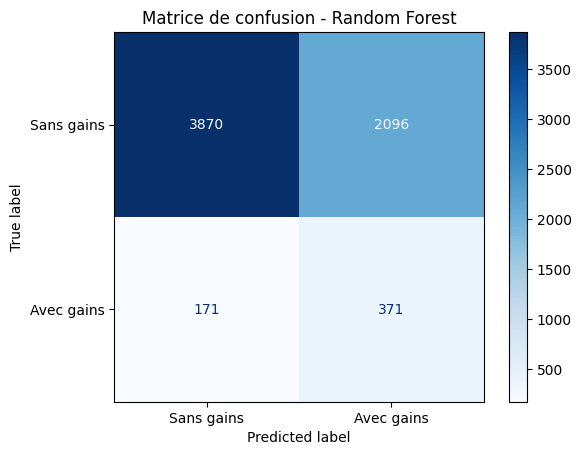

In [45]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=['Sans gains', 'Avec gains'], cmap='Blues')
plt.title("Matrice de confusion - Random Forest")
plt.show()

Le modèle trouve environ **7 personnes avec gains sur 10** (rappel ≈ 0.72). En contrepartie, il cible beaucoup de personnes qui n'en ont pas (précision ≈ 0.15).

**Est-ce acceptable pour l'organisme ?** Oui. Une action de sensibilisation à l'épargne coûte peu, et elle n'est pas nuisible pour une personne qui n'a pas encore de gains en capital (elle peut même lui être utile). Il est donc plus grave de **manquer** une personne concernée que d'en contacter une de trop. C'est pour cela qu'on privilégie le **rappel**.

## Courbe ROC

La courbe ROC montre la capacité du modèle à séparer les deux groupes. La diagonale correspond au hasard. Plus la courbe est au-dessus de la diagonale, meilleur est le modèle.

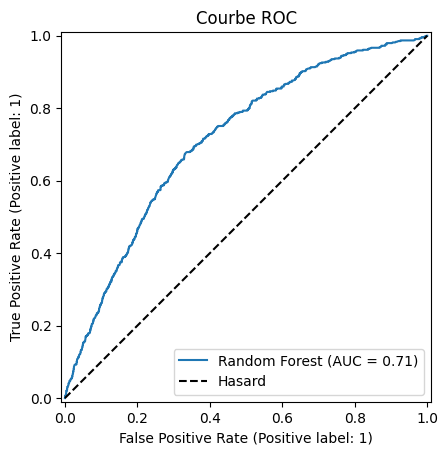

In [46]:
RocCurveDisplay.from_predictions(y_test, probabilites, name='Random Forest')
plt.plot([0, 1], [0, 1], 'k--', label='Hasard')
plt.legend()
plt.title("Courbe ROC")
plt.show()

## Utilisation concrète : cibler les profils les plus probables

Comme le modèle ne peut pas prédire avec certitude, on l'utilise plutôt pour **classer** les personnes selon leur probabilité. Si l'organisme n'a le budget que pour contacter **20 %** des personnes, combien de personnes avec gains va-t-il atteindre ?

In [47]:
nombre_cible = int(len(probabilites) * 0.20)
indices_cibles = np.argsort(-probabilites)[:nombre_cible]

trouves = y_test.values[indices_cibles].sum()
total = y_test.sum()

print("Personnes contactées        :", nombre_cible, "(20 % de la population)")
print("Personnes avec gains        :", trouves, "sur", total)
print("Part des personnes trouvées :", round(trouves / total * 100, 1), "%")
print("Au hasard, on en trouverait : 20 %")

Personnes contactées        : 1301 (20 % de la population)
Personnes avec gains        : 228 sur 542
Part des personnes trouvées : 42.1 %
Au hasard, on en trouverait : 20 %


En contactant les 20 % de personnes jugées les plus probables, l'organisme atteint environ **42 %** des personnes ayant des gains en capital, soit **plus de deux fois plus** qu'en choisissant au hasard. C'est le vrai apport du modèle pour l'objectif métier.

## Interprétation : quelles variables comptent le plus ?

On utilise l'**importance par permutation** : on mélange au hasard les valeurs d'une variable, puis on regarde de combien le ROC-AUC baisse. Plus la baisse est forte, plus le modèle a besoin de cette variable.

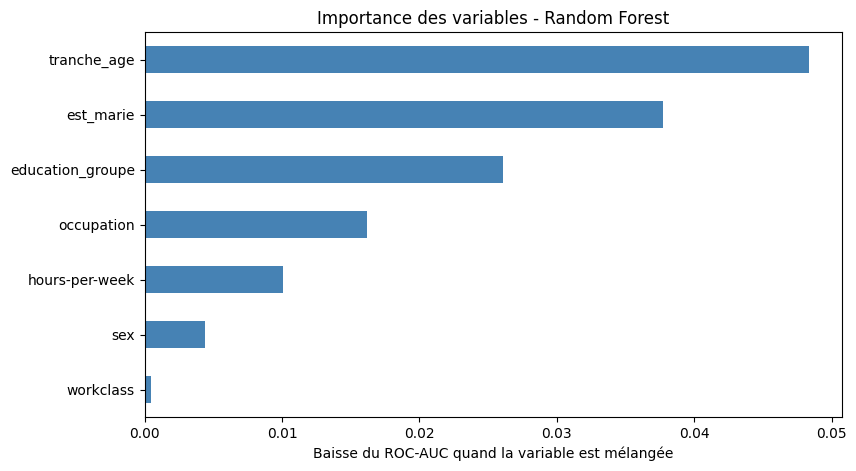

,0
tranche_age,0.048
est_marie,0.038
education_groupe,0.026
occupation,0.016
hours-per-week,0.010
sex,0.004
workclass,0.000


In [48]:
importance = permutation_importance(modele_choisi, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=42)
importance = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(9, 5))
importance.plot(kind='barh', color='steelblue')
plt.title("Importance des variables - Random Forest")
plt.xlabel("Baisse du ROC-AUC quand la variable est mélangée")
plt.show()

importance.sort_values(ascending=False).round(3)

Les **3 variables les plus importantes** pour le modèle sont exactement celles de notre **objectif Data Science** : la **tranche d'âge**, l'**indicateur « marié »** et le **niveau d'études regroupé**. Cela confirme la sélection des caractéristiques faite à la Partie 4.

`workclass` a une importance presque nulle : on pourrait la retirer sans perdre de performance.

# Conclusion

| Étape | Résultat |
|---|---|
| Type de problème | Classification binaire de `capital-gain > 0` |
| Algorithmes testés | Arbre de décision, Random Forest, Gradient Boosting, KNN, Naive Bayes |
| Performances | KNN rejeté (rappel 0) ; Random Forest en tête : F1 ≈ 0.22, ROC-AUC ≈ 0.70 en validation croisée |
| Modèle choisi | **Random Forest** (meilleures performances, stable, interprétable) |
| Mesure privilégiée | **Rappel** (≈ 0.72 sur le test), car il vaut mieux contacter une personne de trop que manquer une personne concernée |
| Apport pour l'organisme | En ciblant 20 % de la population, on atteint environ 42 % des personnes avec gains (plus de 2 fois mieux que le hasard) |
| Variables clés | Tranche d'âge, marié, niveau d'études regroupé (celles de l'objectif Data Science) |

**Limite :** les variables du dataset expliquent mal le fait d'avoir des gains en capital, comme le montrait la matrice de corrélation (liens ≈ 0.13). Pour améliorer le modèle, il faudrait des données supplémentaires sur le patrimoine ou l'épargne des personnes, et non un modèle plus complexe.

# Partie 6 : Évaluation approfondie du modèle choisi

À la Partie 5, on a choisi la **Random Forest** et calculé ses scores principaux. Cette partie vérifie plus en détail si le modèle est **fiable** et **adapté au but de l'organisme** :

1. Le rapport de classification complet.
2. La comparaison des 5 algorithmes sur le jeu de test (courbes ROC et précision-rappel).
3. La stabilité du modèle.
4. Le choix du seuil de décision.
5. La courbe de gain (efficacité du ciblage).
6. La courbe d'apprentissage (faut-il plus de données ?).
7. L'analyse par groupe de population (le modèle est-il équitable ?).

In [49]:
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, average_precision_score
from sklearn.model_selection import cross_val_predict, learning_curve

## 1. Rapport de classification

Ce rapport donne la précision, le rappel et le F1 **pour chaque classe** :
* classe **0** : personnes sans gains en capital ;
* classe **1** : personnes avec gains en capital (celles que l'organisme veut trouver).

In [50]:
print(classification_report(y_test, predictions, target_names=['Sans gains (0)', 'Avec gains (1)']))

                precision    recall  f1-score   support

Sans gains (0)       0.96      0.65      0.77      5966
Avec gains (1)       0.15      0.68      0.25       542

      accuracy                           0.65      6508
     macro avg       0.55      0.67      0.51      6508
  weighted avg       0.89      0.65      0.73      6508



**Lecture :**
* Pour la classe 1, le **rappel est de 0.71** : le modèle trouve 71 % des personnes avec gains.
* Sa **précision est de 0.14** : parmi les personnes ciblées, 14 % ont vraiment des gains. C'est presque **2 fois** le taux de base (8 %), donc le ciblage est meilleur qu'au hasard.
* Pour la classe 0, la précision est de **0.96** : quand le modèle dit « non », il a presque toujours raison.
* L'**accuracy** (0.63) est plus basse que celle du modèle « toujours non » (0.92). C'est normal : notre modèle accepte de faire des erreurs sur la classe 0 pour trouver la classe 1, qui est la plus importante pour l'organisme.

## 2. Comparaison des 5 algorithmes sur le jeu de test

À la Partie 5, la comparaison a été faite en validation croisée sur l'entraînement. On vérifie maintenant sur le jeu de test que la Random Forest reste parmi les meilleurs.

* **Courbe ROC** : plus la courbe est haute, mieux l'algorithme sépare les deux classes.
* **Courbe précision-rappel** : elle est plus adaptée aux données déséquilibrées. La ligne pointillée correspond au hasard (8 % de positifs). L'**AP** (précision moyenne) résume cette courbe : plus elle est haute, mieux c'est.

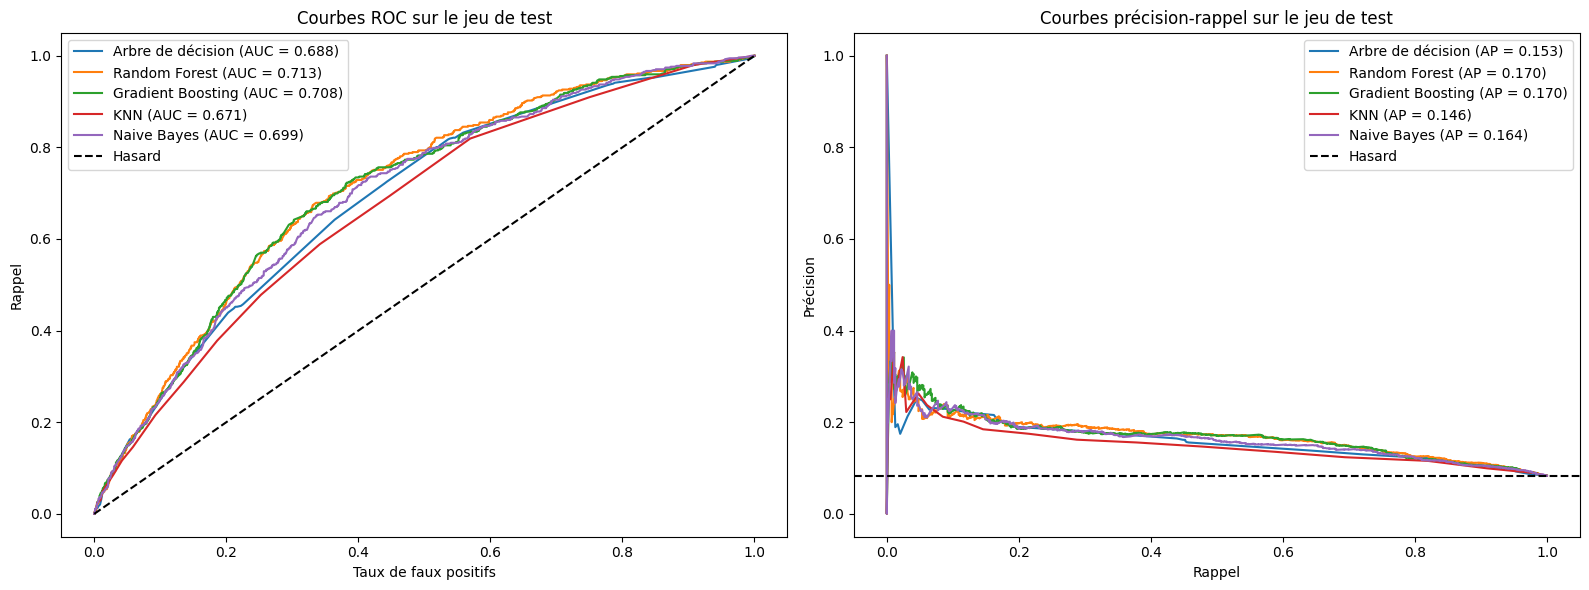

In [51]:
probabilites_test = {}
for nom, modele in modeles.items():
    pipeline = Pipeline([('preparation', preparation), ('modele', modele)])
    pipeline.fit(X_train, y_train)
    probabilites_test[nom] = pipeline.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for nom, proba in probabilites_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{nom} (AP = {average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', label='Hasard')
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Rappel")
axes[0].set_title("Courbes ROC sur le jeu de test")
axes[0].legend()

axes[1].axhline(y_test.mean(), color='black', linestyle='--', label='Hasard')
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Précision")
axes[1].set_title("Courbes précision-rappel sur le jeu de test")
axes[1].legend()

plt.tight_layout()
plt.show()

Sur le jeu de test, la **Random Forest** et le **Gradient Boosting** ont les courbes les plus hautes, et le **KNN** la plus basse. Le choix fait à la Partie 5 est donc **confirmé** sur des données jamais vues.

Toutes les courbes précision-rappel restent au-dessus de la ligne du hasard, mais pas très haut : c'est la conséquence des liens faibles entre les variables et la cible, observés dès la matrice de corrélation.

## 3. Stabilité du modèle

Un bon modèle doit donner des scores **proches** d'un découpage des données à l'autre. On regarde la moyenne et l'**écart-type** des scores sur les 5 plis de la validation croisée. Un petit écart-type signifie que le modèle est stable.

In [52]:
scores_stabilite = cross_validate(modele_choisi, X_train, y_train, cv=validation, scoring=mesures)

stabilite = pd.DataFrame({
    'Moyenne': [scores_stabilite['test_' + m].mean() for m in mesures],
    'Écart-type': [scores_stabilite['test_' + m].std() for m in mesures]
}, index=list(mesures)).round(3)
stabilite

,Moyenne,Écart-type
Rappel,0.629,0.014
Précision,0.140,0.004
F1,0.229,0.005
ROC-AUC,0.696,0.009


Les écarts-types sont **petits** par rapport aux moyennes : les performances ne dépendent presque pas du découpage des données. Le modèle est **stable**, on peut donc faire confiance à ses résultats.

## 4. Choix du seuil de décision

Par défaut, le modèle répond « a des gains » si la probabilité est d'au moins **0.5**. Ce seuil peut être changé :
* un seuil **plus bas** trouve plus de personnes avec gains (rappel plus haut), mais cible plus de monde ;
* un seuil **plus haut** cible moins de monde, mais en trouve moins.

**Important :** on choisit le seuil sur le jeu d'**entraînement** (avec `cross_val_predict`), pour ne pas tricher avec le jeu de test.

In [53]:
probabilites_train = cross_val_predict(modele_choisi, X_train, y_train, cv=validation, method='predict_proba')[:, 1]

lignes = []
for seuil in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    pred = (probabilites_train >= seuil).astype(int)
    lignes.append([seuil, recall_score(y_train, pred), precision_score(y_train, pred, zero_division=0),
                   f1_score(y_train, pred), pred.mean()])

tableau_seuils = pd.DataFrame(lignes, columns=['Seuil', 'Rappel', 'Précision', 'F1', 'Part de la population ciblée']).round(3)
tableau_seuils

,Seuil,Rappel,Précision,F1,Part de la population ciblée
0,0.30,0.935,0.101,0.182,0.775
1,0.35,0.881,0.109,0.194,0.673
2,0.40,0.837,0.118,0.207,0.589
3,0.45,0.759,0.127,0.217,0.499
4,0.50,0.629,0.140,0.229,0.376
5,0.55,0.484,0.162,0.243,0.249
6,0.60,0.320,0.185,0.235,0.144
7,0.65,0.212,0.218,0.215,0.081
8,0.70,0.116,0.250,0.158,0.039


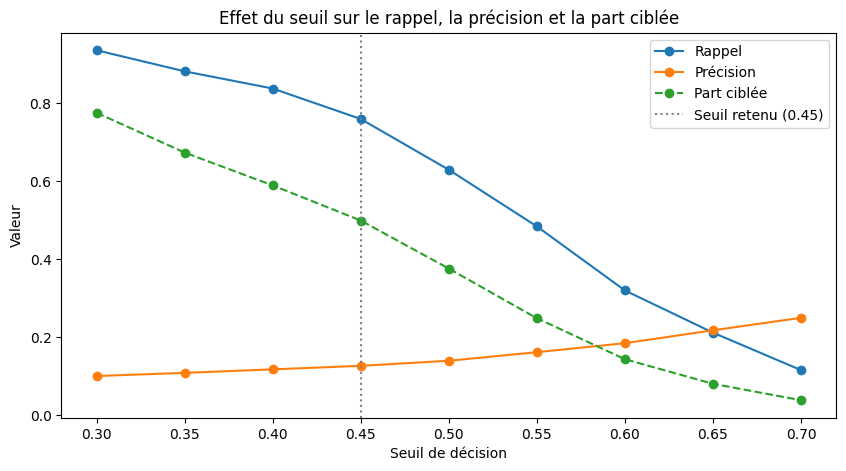

In [54]:
plt.figure(figsize=(10, 5))
plt.plot(tableau_seuils['Seuil'], tableau_seuils['Rappel'], marker='o', label='Rappel')
plt.plot(tableau_seuils['Seuil'], tableau_seuils['Précision'], marker='o', label='Précision')
plt.plot(tableau_seuils['Seuil'], tableau_seuils['Part de la population ciblée'], marker='o', linestyle='--', label='Part ciblée')
plt.axvline(0.45, color='grey', linestyle=':', label='Seuil retenu (0.45)')
plt.xlabel("Seuil de décision")
plt.ylabel("Valeur")
plt.title("Effet du seuil sur le rappel, la précision et la part ciblée")
plt.legend()
plt.show()

**Lecture du tableau :**
* Avec le seuil **0.50**, on trouve environ **66 %** des personnes avec gains en ciblant **40 %** de la population.
* Avec le seuil **0.45**, on trouve environ **79 %** des personnes avec gains en ciblant **53 %** de la population.
* En dessous de 0.45, le rappel monte encore, mais on cible plus de 60 % de la population : le ciblage perd son intérêt.

**Choix :** pour l'organisme, manquer une personne concernée est plus grave que contacter une personne de trop. On retient donc le seuil **0.45**, qui trouve environ 8 personnes avec gains sur 10 tout en ciblant à peu près la moitié de la population.

Ce seuil reste un **choix métier** : si l'organisme a un budget plus petit, il peut prendre un seuil plus haut.

On vérifie maintenant ce seuil sur le jeu de test :

In [55]:
seuil_retenu = 0.45
predictions_seuil = (probabilites >= seuil_retenu).astype(int)

print("Seuil 0.50 -> Rappel :", round(recall_score(y_test, predictions), 3),
      "| Précision :", round(precision_score(y_test, predictions), 3),
      "| Part ciblée :", round(predictions.mean(), 3))
print("Seuil 0.45 -> Rappel :", round(recall_score(y_test, predictions_seuil), 3),
      "| Précision :", round(precision_score(y_test, predictions_seuil), 3),
      "| Part ciblée :", round(predictions_seuil.mean(), 3))

Seuil 0.50 -> Rappel : 0.685 | Précision : 0.15 | Part ciblée : 0.379
Seuil 0.45 -> Rappel : 0.788 | Précision : 0.13 | Part ciblée : 0.504


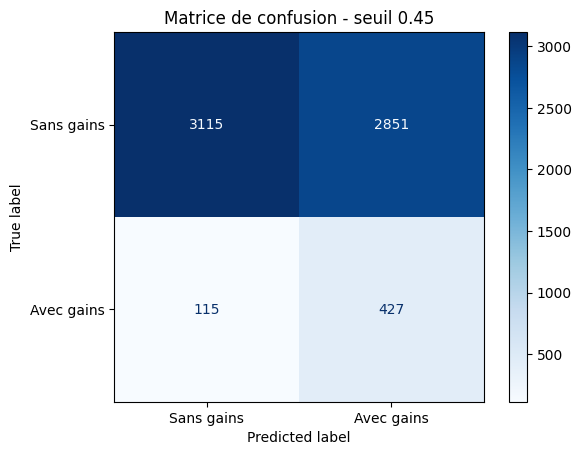

In [56]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions_seuil, display_labels=['Sans gains', 'Avec gains'], cmap='Blues')
plt.title("Matrice de confusion - seuil 0.45")
plt.show()

Sur le jeu de test, le seuil 0.45 donne un rappel d'environ **0.80** : le résultat obtenu sur l'entraînement se confirme. Le nombre de personnes avec gains manquées (en bas à gauche) diminue nettement par rapport au seuil 0.50.

## 5. Courbe de gain cumulé

Cette courbe répond à la question : *si l'organisme contacte les X % de personnes les plus probables selon le modèle, quel pourcentage des personnes avec gains atteint-il ?*

* La **diagonale** correspond à un ciblage au hasard.
* Plus la courbe du modèle est **au-dessus** de la diagonale, plus le ciblage est efficace.

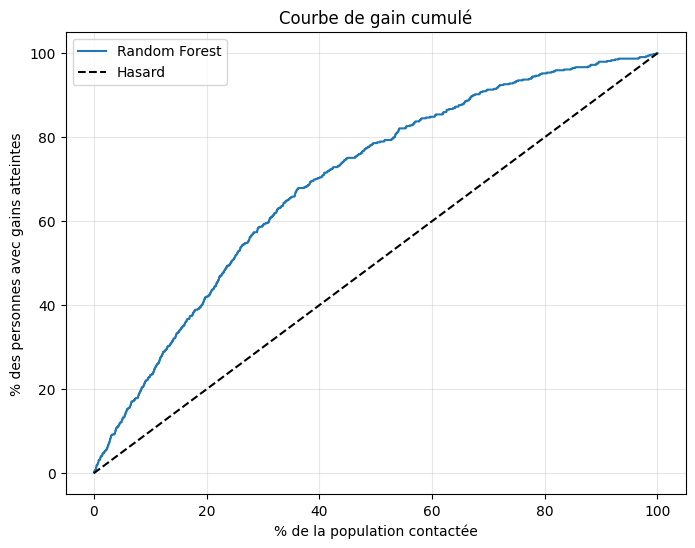

,% contactés,% de personnes avec gains atteintes,Gain par rapport au hasard
0,10,23.2,2.32
1,20,42.1,2.10
2,30,59.0,1.97
3,40,70.3,1.76
4,50,78.6,1.57


In [57]:
ordre = np.argsort(-probabilites)
gains_cumules = np.cumsum(y_test.values[ordre]) / y_test.sum()
part_contactee = np.arange(1, len(ordre) + 1) / len(ordre)

plt.figure(figsize=(8, 6))
plt.plot(part_contactee * 100, gains_cumules * 100, label='Random Forest')
plt.plot([0, 100], [0, 100], 'k--', label='Hasard')
plt.xlabel("% de la population contactée")
plt.ylabel("% des personnes avec gains atteintes")
plt.title("Courbe de gain cumulé")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

tableau_gain = pd.DataFrame({
    '% contactés': [10, 20, 30, 40, 50],
    '% de personnes avec gains atteintes': [round(gains_cumules[int(len(ordre) * p / 100) - 1] * 100, 1) for p in [10, 20, 30, 40, 50]]
})
tableau_gain['Gain par rapport au hasard'] = (tableau_gain['% de personnes avec gains atteintes'] / tableau_gain['% contactés']).round(2)
tableau_gain

En contactant **20 %** de la population, l'organisme atteint environ **42 %** des personnes avec gains, soit **2.1 fois mieux** que le hasard. En contactant **50 %**, il en atteint environ **79 %**.

Ce tableau est directement utile à l'organisme : il peut choisir combien de personnes contacter selon son budget, et savoir à l'avance quelle part du public visé il touchera.

## 6. Courbe d'apprentissage

Cette courbe montre l'évolution du ROC-AUC quand on entraîne le modèle avec de plus en plus de données :
* si l'écart entre entraînement et validation est **grand**, le modèle apprend par cœur (sur-apprentissage) ;
* si la courbe de validation **monte encore**, plus de données amélioreraient le modèle ;
* si elle est **plate**, ajouter des personnes ne servirait à rien.

(Cette cellule peut prendre environ une minute.)

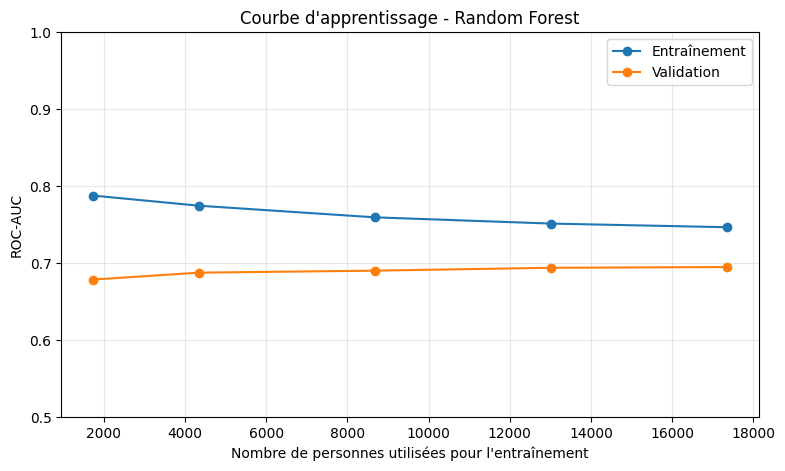

In [58]:
tailles, scores_train, scores_validation = learning_curve(
    modele_choisi, X_train, y_train, cv=3, scoring='roc_auc',
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], n_jobs=-1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, scores_train.mean(axis=1), marker='o', label='Entraînement')
plt.plot(tailles, scores_validation.mean(axis=1), marker='o', label='Validation')
plt.xlabel("Nombre de personnes utilisées pour l'entraînement")
plt.ylabel("ROC-AUC")
plt.title("Courbe d'apprentissage - Random Forest")
plt.ylim(0.5, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Lecture :**
* L'écart entre entraînement (≈ 0.74) et validation (≈ 0.70) est **petit** et diminue : il n'y a pas de sur-apprentissage.
* La courbe de validation devient **presque plate** à partir d'environ 10 000 personnes.

**Conclusion :** ajouter des personnes dans le dataset n'améliorerait pas le modèle. Pour faire mieux, il faudrait **d'autres variables** (patrimoine, épargne, héritage), ce qui confirme la limite observée dès la matrice de corrélation.

## 7. Le modèle est-il équitable ? Analyse par groupe

L'organisme ne doit pas oublier certains publics dans ses actions de sensibilisation. On calcule donc le **rappel** du modèle pour chaque groupe : quel pourcentage des personnes avec gains est trouvé dans chaque groupe ?

In [59]:
analyse = X_test.copy()
analyse['reel'] = y_test.values
analyse['predit'] = predictions

def resume_groupe(groupe):
    return pd.Series({
        'Nombre de personnes': len(groupe),
        'Taux réel avec gains': round(groupe['reel'].mean(), 3),
        'Rappel': round(recall_score(groupe['reel'], groupe['predit'], zero_division=0), 3),
        'Part ciblée': round(groupe['predit'].mean(), 3)
    })

print("Par sexe :")
display(analyse.groupby('sex').apply(resume_groupe))
print("Par tranche d'âge :")
display(analyse.groupby('tranche_age').apply(resume_groupe))

Par sexe :


/tmp/ipykernel_3133/2963365324.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(analyse.groupby('sex').apply(resume_groupe))


,Nombre de personnes,Taux réel avec gains,Rappel,Part ciblée
sex,,,,
Female,2142.0,0.056,0.442,0.152
Male,4366.0,0.097,0.754,0.490


Par tranche d'âge :


/tmp/ipykernel_3133/2963365324.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(analyse.groupby('tranche_age').apply(resume_groupe))


,Nombre de personnes,Taux réel avec gains,Rappel,Part ciblée
tranche_age,,,,
17-25,1285.0,0.030,0.000,0.002
26-35,1692.0,0.064,0.417,0.204
36-45,1607.0,0.104,0.760,0.577
46-55,1093.0,0.121,0.871,0.597
56-65,611.0,0.088,0.852,0.584
66+,220.0,0.191,0.905,0.832


**Lecture :**
* **Par sexe :** le modèle trouve environ **79 %** des hommes avec gains, mais seulement environ **45 %** des femmes. Une partie de l'écart vient de la réalité (les femmes du dataset ont moins souvent des gains : 5.6 % contre 9.7 %), mais le modèle **amplifie** cette différence.
* **Par âge :** le modèle ne cible presque aucun jeune de 17-25 ans (rappel de 0). À l'inverse, il trouve environ 90 % des personnes de 66 ans et plus.

C'est un **risque pour l'objectif métier** : des femmes et des jeunes qui ont des revenus du capital ne recevraient pas les actions de sensibilisation. Or les jeunes sont justement un public intéressant pour l'éducation à l'épargne.

### Test : retirer la variable `sex`

À la Partie 4, `sex` avait déjà été signalée comme « à utiliser avec prudence ». On entraîne le même modèle **sans** cette variable pour voir si l'on perd en performance.

In [60]:
variables_sans_sexe = [c for c in variables_categorielles if c != 'sex']

preparation_sans_sexe = ColumnTransformer([
    ('texte', OneHotEncoder(handle_unknown='ignore', sparse_output=False), variables_sans_sexe),
    ('nombres', StandardScaler(), variables_numeriques_modele)
])
modele_sans_sexe = Pipeline([('preparation', preparation_sans_sexe), ('modele', modeles['Random Forest'])])
modele_sans_sexe.fit(X_train.drop(columns='sex'), y_train)

proba_sans_sexe = modele_sans_sexe.predict_proba(X_test.drop(columns='sex'))[:, 1]
pred_sans_sexe = (proba_sans_sexe >= 0.5).astype(int)

comparaison = pd.DataFrame({
    'Avec sex': [roc_auc_score(y_test, probabilites), recall_score(y_test, predictions), f1_score(y_test, predictions),
                 recall_score(y_test[X_test['sex'] == 'Female'], predictions[(X_test['sex'] == 'Female').values])],
    'Sans sex': [roc_auc_score(y_test, proba_sans_sexe), recall_score(y_test, pred_sans_sexe), f1_score(y_test, pred_sans_sexe),
                 recall_score(y_test[X_test['sex'] == 'Female'], pred_sans_sexe[(X_test['sex'] == 'Female').values])]
}, index=['ROC-AUC', 'Rappel', 'F1', 'Rappel chez les femmes']).round(3)
comparaison

,Avec sex,Sans sex
ROC-AUC,0.713,0.710
Rappel,0.685,0.681
F1,0.247,0.251
Rappel chez les femmes,0.442,0.500


Sans la variable `sex`, les performances globales sont **identiques** (ROC-AUC, rappel et F1 presque inchangés), et le rappel chez les femmes **augmente** (de 0.45 à 0.52).

**Recommandation :** retirer `sex` du modèle final. On ne perd rien en performance, et le ciblage devient plus équitable. L'écart restant vient d'autres variables (par exemple `est_marie`) et de la réalité des données. L'organisme pourrait le compenser par des actions spécifiques pour les femmes et les jeunes.

# Conclusion de l'évaluation

| Point vérifié | Résultat |
|---|---|
| Rapport de classification | Rappel de 0.71 sur la classe « avec gains », précision 2 fois supérieure au hasard |
| Comparaison sur le test | La Random Forest reste parmi les meilleurs : le choix est confirmé |
| Stabilité | Écarts-types faibles : le modèle est stable |
| Seuil de décision | Seuil **0.45** retenu : environ 8 personnes avec gains sur 10 trouvées |
| Courbe de gain | 20 % de la population contactée → environ 42 % des personnes avec gains atteintes |
| Courbe d'apprentissage | Pas de sur-apprentissage ; plus de données n'aideraient pas, il faut d'autres variables |
| Équité | Le modèle trouve moins bien les femmes et les jeunes ; retirer `sex` ne coûte rien en performance |

**Bilan :** la Random Forest est un modèle **fiable et stable** pour aider l'organisme à **prioriser** ses actions de sensibilisation. Elle ne prédit pas avec certitude, car les variables du dataset expliquent peu la présence de gains en capital, mais elle cible **2 fois mieux que le hasard**. Pour l'utiliser, on recommande le seuil 0.45, le retrait de la variable `sex`, et une attention particulière aux publics jeunes et féminins.